# PSA_Event: 吸収点と 1 ヒットの判定(Reconstruct へ渡す)

`PSA_Calibration` までは、ヒットを「ボード ha04 の ch2 のピクセル (n = 5, m = 3)、エネルギー E」という**検出器の中の番号**で持っています。
コンプトンの再構成(`Reconstruct`)には、**検出器座標での吸収点 $P_g$ [mm] と散乱ガンマ線のエネルギー $E_g$** が要ります。
`PSA_Event` はその間をつなぐモジュールで、SMILE-2+ の `HA_Calc` の後半(ピクセル → 吸収点、シングルヒットの判定)に当たります。

| 手順 | 中身 |
|---|---|
| 1. 使えるヒット | ピクセルがあり(`pixel >= 0`)、`energy > energy_min` で、そのブロック(board, ch)が `geometry_file` にあるヒット |
| 2. 吸収点 | $P_g = (x_0, y_0, z_0) + \mathrm{pitch}\,[(n - 4.5)\,\mathbf u + (m - 4.5)\,\mathbf v]$ [mm] |
| 3. ヒットの数 | 使えるヒットが 1 つ: `PSA_SingleHit`、2 つ以上: `PSA_MultiHit`、0: `PSA_NoHits`(イベント選択のフラグ。イベントは飛ばさない) |

`Reconstruct` は、`PSA_SingleHit` のイベントで $E_g$, $P_g$ を受け取り、`Reconstruct/single_hit` に書きます
(SMILE-2+ のデータでは `HA_Calc_2p` → `Reconstruct_2p`)。

### ジオメトリのファイル `calib/psa/geometry.csv`

1 行に 1 ブロックです(単位 mm、座標は [0_Introduction](../../../0_Introduction/Introduction.ipynb) のもの: 原点は μ-PIC の中央、X は W → E、Y は N → S、Z は下向き)。

```
board,ch,x0,y0,z0,ux,uy,uz,vx,vy,vz,pitch
```

| 列 | 中身 |
|---|---|
| `x0, y0, z0` | 8 × 8 のブロックの中心 |
| `ux, uy, uz` | ピクセル番号 n が増える向きの単位ベクトル |
| `vx, vy, vz` | m が増える向きの単位ベクトル |
| `pitch` | ピクセルの間隔 |

> **今の状態**: `geometry.csv` は CAD の STEP ファイルと HA の配置図から `scripts/calib/make_psa_geometry.py` で作ったもの(18 HA × 6 ch)、
> エネルギーは Cs-137 と Co-60 から作った `energy_haNN.csv`(ha04 は無い)です。ピクセルの向き(u, v)は配線でも変わるので、データでの確認がまだです。

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import ROOT
ROOT.gROOT.SetBatch(True)

# リポジトリの場所、チェーンの実行スクリプト、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
RUN_CHAIN = REPO / "run_script" / "run_chain.py"
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CACHE = REPO / "tutorials" / "cache"   # チェーンの出力の置き場(チュートリアル間で共有、git には入れない)
CACHE.mkdir(exist_ok=True)

def th2(h):
    """ROOT の TH2 -> (中身 [x のビン, y のビン], x のビンの端, y のビンの端)"""
    nx, ny = h.GetNbinsX(), h.GetNbinsY()
    dt = np.float32 if h.InheritsFrom("TArrayF") else np.float64   # TH2F / TH2D
    a = np.frombuffer(h.GetArray(), dtype=dt, count=(nx + 2) * (ny + 2)).reshape(ny + 2, nx + 2).astype(float)
    ex = np.array([h.GetXaxis().GetBinLowEdge(i) for i in range(1, nx + 2)])
    ey = np.array([h.GetYaxis().GetBinLowEdge(i) for i in range(1, ny + 2)])
    return a[1:-1, 1:-1].T.copy(), ex, ey

def show_params(config, module):
    """設定ファイルの、あるモジュールのパラメータを、説明(_doc)と単位(_units)つきで表示する"""
    p = json.load(open(REPO / "config" / f"{config}.json"))["parameters"][module]
    doc, units = p.get("_doc", {}), p.get("_units", {})
    for k, v in p.items():
        if k.startswith("_"):
            continue
        u = f" [{units[k]}]" if k in units else ""
        print(f"{k} = {json.dumps(v, ensure_ascii=False)}{u}\n    {doc.get(k, '')}")

## 1. データの準備

TPC と PSA を一緒に読むので、ETCC のラン **`20261102_run04`**(211 イベント)を使います。
ファイルは 2 つの storage に分かれているので、片方を `--data-dir`、もう片方を `--extra-data-dir` で渡します(`ReadData` と `PSA_ReadData` の `extra_data_dirs` に入る)。

In [2]:
DATA = Path(os.environ.get("SMILE3_FM_DATA", "/mnt/nas_eureka/SMILE-3FM_data"))
RUN = "20261102_run04"
SRC = [DATA / "20261102" / "calltt" / RUN, DATA / "20261102" / "killua" / RUN]
for d in SRC:
    print("OK     " if d.is_dir() else "MISSING", d)
RUN_DIR, EXTRA_DIR = SRC   # calltt(アノード、ha06〜ha16)と killua(カソード、ha00〜ha05)
print(sum(len(list(d.glob("ha*_*.dat"))) + len(list(d.glob("tpc_enc_*.raw"))) for d in SRC), "files")

OK      /mnt/nas_eureka/SMILE-3FM_data/20261102/calltt/20261102_run04
OK      /mnt/nas_eureka/SMILE-3FM_data/20261102/killua/20261102_run04
37 files


## 2. 流す

設定ファイル `smile3_reconstruct`(`ReadData → PSA_* → CalcFADC → TPC_Calibration → PSA_Event → TOT_Skewness → Reconstruct`)で、`calib/psa` の較正ファイルを使って流します。
`PSA_Event/NHits` は 1 イベントの使えるヒットの数です。

In [3]:
def run_chain(out, *args):
    cmd = [sys.executable, str(RUN_CHAIN), "smile3_reconstruct", "-o", str(out), "--data-dir", str(RUN_DIR),
           "--extra-data-dir", str(EXTRA_DIR), *args]
    print(" ".join(cmd))
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
    r.check_returncode()
    return r

OUT = CACHE / f"reconstruct_{RUN}.root"
r = run_chain(OUT)
print("\n".join(l for l in (r.stdout + r.stderr).splitlines() if l.startswith("PSA_Event")))
for l in r.stdout.splitlines():
    if l.startswith(("PSA_SingleHit", "PSA_MultiHit", "PSA_NoHits", "NotConformEnergy")):
        print(l)
f = ROOT.TFile(str(OUT))
h = f.Get("PSA_Event/NHits")
print("NHits:", {int(h.GetBinCenter(i)): int(h.GetBinContent(i)) for i in range(1, h.GetNbinsX() + 1) if h.GetBinContent(i)})

/usr/bin/python3 /home/onoda/ANLNext/Erica_git_dev/EricaNext/run_script/run_chain.py smile3_reconstruct -o /home/onoda/ANLNext/Erica_git_dev/EricaNext/tutorials/cache/reconstruct_20261102_run04.root --data-dir /mnt/nas_eureka/SMILE-3FM_data/20261102/calltt/20261102_run04 --extra-data-dir /mnt/nas_eureka/SMILE-3FM_data/20261102/killua/20261102_run04


PSA_Event: geometry of 78 blocks of this run from /home/onoda/ANLNext/Erica_git_dev/EricaNext/calib/psa/geometry.csv
NotConformEnergy                                            7                0
PSA_MultiHit                                              138              136
PSA_NoHits                                                 10               10
PSA_SingleHit                                              63               56
NHits: {0: 10, 1: 63, 2: 65, 3: 50, 4: 17, 5: 6}


## 3. 式どおりか確かめる

`PSA_SingleHit` のイベントのうち、TPC のエネルギーがあり(`TPC_Ee_Valid`)、`Reconstruct` で運動学が合うものが `single_hit` に入ります。
`single_hit` の `evt_id`(トリガーカウンタ)で `PSA_TreeWriter/psa` の行と結び付け、$E_g$ がそのヒットの `energy`、$P_g$ が `geometry.csv` から手順 2 の式で出したものと同じかを確かめます。

In [4]:
import csv
geo = {(int(r["board"]), int(r["ch"])): r for r in csv.DictReader(l for l in open(REPO / "calib" / "psa" / "geometry.csv") if not l.startswith("#"))}
p = ROOT.RDataFrame("PSA_TreeWriter/psa", str(OUT)).AsNumpy(["trig", "board", "ch", "pix_n", "pix_m", "pixel", "energy"])
for k in ["board", "ch", "pix_n", "pix_m", "pixel"]:
    p[k] = p[k].astype(int)
s = ROOT.RDataFrame("Reconstruct/single_hit", str(OUT)).AsNumpy(["evt_id", "Eg", "Pg"])
emin = ec.load("smile3_reconstruct")["parameters"]["PSA_Event"]["energy_min"]
used = (p["pixel"] >= 0) & (p["energy"] > emin) & np.array([(b, c) in geo for b, c in zip(p["board"], p["ch"])])
n_bad = 0
for t_, eg, pg in zip(s["evt_id"], s["Eg"], s["Pg"]):
    k = np.where(used & (p["trig"] == t_))[0]
    assert len(k) == 1          # single_hit のイベントには、使えるヒットがちょうど 1 つ
    k = k[0]
    g = geo[(p["board"][k], p["ch"][k])]
    v = lambda *names: np.array([float(g[n]) for n in names])
    expect = v("x0", "y0", "z0") + float(g["pitch"]) * ((p["pix_n"][k] - 4.5) * v("ux", "uy", "uz") + (p["pix_m"][k] - 4.5) * v("vx", "vy", "vz"))
    n_bad += abs(eg - p["energy"][k]) > 1e-6 or np.abs(np.asarray(pg) - expect).max() > 1e-6
print(len(s["evt_id"]), "rows in single_hit, rows that differ from the formula:", n_bad)

53 rows in single_hit, rows that differ from the formula: 0


ericanext_config: WARNING: no storage_g*/ in /home/onoda/ANLNext/Erica_git_dev/EricaNext/mount_data (from DATA_DIR (mount_data/)). SMILE3_DATA must be the directory that holds storage_g0/ etc.
ericanext_config: WARNING: no storage_g*/ in /home/onoda/ANLNext/Erica_git_dev/EricaNext/mount_data (from DATA_DIR (mount_data/)). SMILE3_DATA must be the directory that holds storage_g0/ etc.


吸収点を、上から見た図(X-Y)と横から見た図(X-Z、Y-Z)に描きます。灰色は `geometry.csv` の全ブロックの中心です。
底面(Z ≈ 346 mm)と 4 つの側面(X, Y = ±183.5 mm)のブロックに入っています。

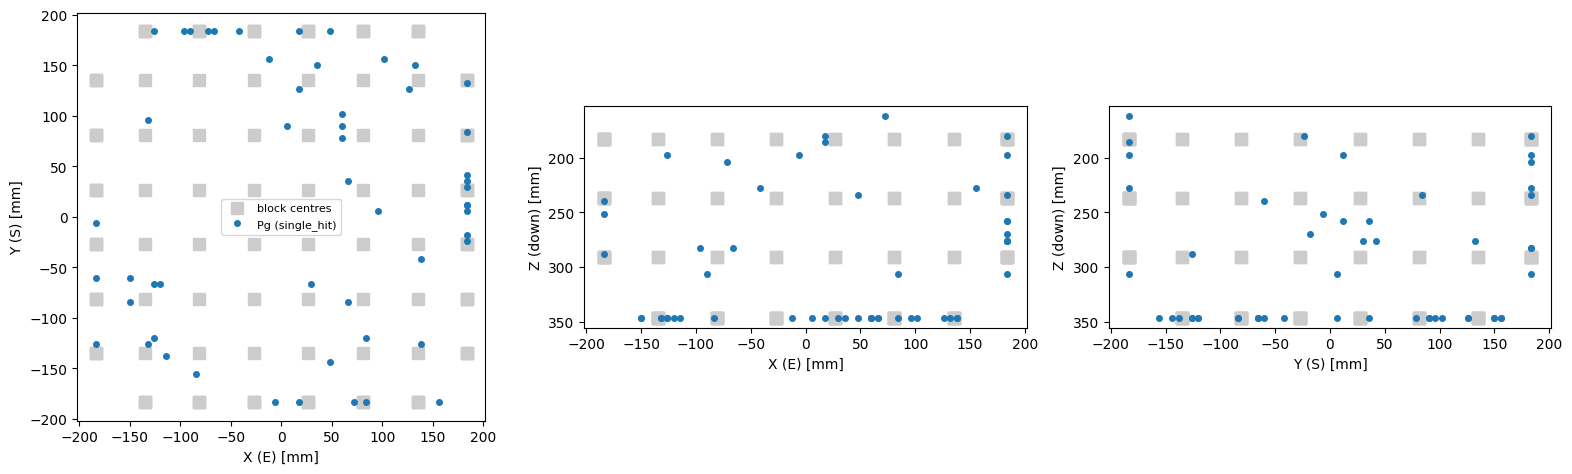

In [5]:
pg = np.stack([np.asarray(v) for v in s["Pg"]])
c = np.array([[float(r["x0"]), float(r["y0"]), float(r["z0"])] for r in geo.values()])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for a, (i, j, xl, yl) in zip(axs, [(0, 1, "X (E) [mm]", "Y (S) [mm]"), (0, 2, "X (E) [mm]", "Z (down) [mm]"), (1, 2, "Y (S) [mm]", "Z (down) [mm]")]):
    a.plot(c[:, i], c[:, j], "s", color="0.8", ms=9, label="block centres")
    a.plot(pg[:, i], pg[:, j], "o", ms=4, label="Pg (single_hit)")
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_aspect("equal")
    if j == 2:
        a.invert_yaxis()
axs[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. パラメータ

`config/smile3_reconstruct.json` の `PSA_Event` のパラメータです。

In [6]:
show_params("smile3_reconstruct", "PSA_Event")

geometry_file = "{repo}/calib/psa/geometry.csv"
    ブロック(board, ch)ごとの位置と向き(board,ch,x0,y0,z0,ux,uy,uz,vx,vy,vz,pitch)。ピクセル (n, m) の吸収点 = (x0,y0,z0) + pitch((n-4.5)u + (m-4.5)v) [mm]。書き方は config/README.md
energy_min = 0.0 [keV]
    このエネルギーより大きいヒットだけ使う(ピクセルとエネルギーがあり、geometry_file にあるブロックのヒット)
save_hists = true
    true: 使ったヒットの数(NHits)と 1 ヒットのイベントのエネルギー(SingleHitEnergy)を保存する
